# Algorithm Comparison Plus Auxiliary Operations

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import random
import time

In [16]:
def insertion_sort_count(arr):
    a = arr.copy()
    comps = 0
    aux = 0

    for i in range(1, len(a)):
        key = a[i]
        aux += 1
        j = i - 1
        while True:
            comps += 1
            if j >= 0 and a[j] > key:
                a[j + 1] = a[j]
                aux += 1
                j -= 1
            else:
                break
        a[j + 1] = key
        aux += 1

    return comps, aux, comps + aux

In [17]:
def merge_sort_count(arr):
    comps = 0
    aux = 0

    def merge(left, right):
        nonlocal comps, aux
        result = []
        i = j = 0

        while i < len(left) and j < len(right):
            comps += 1
            if left[i] <= right[j]:
                result.append(left[i])
                aux += 1
                i += 1
            else:
                result.append(right[j])
                aux += 1
                j += 1

        aux += len(left) - i
        aux += len(right) - j

        result.extend(left[i:])
        result.extend(right[j:])
        return result

    def sort(a):
        if len(a) <= 1:
            return a
        mid = len(a) // 2
        left = sort(a[:mid])
        right = sort(a[mid:])
        return merge(left, right)

    sorted_arr = sort(arr)
    return comps, aux, comps + aux

In [18]:
def quick_sort_first_count(arr):
    a = arr.copy()
    comps = 0
    aux = 0

    def partition(low, high):
        nonlocal comps, aux
        pivot = a[low]
        aux += 1

        i = low + 1
        for j in range(low + 1, high + 1):
            comps += 1
            if a[j] <= pivot:
                temp = a[i]
                a[i] = a[j]
                a[j] = temp
                aux += 3
                i += 1

        temp = a[low]
        a[low] = a[i - 1]
        a[i - 1] = temp
        aux += 3

        return i - 1

    def qs(low, high):
        if low < high:
            p = partition(low, high)
            qs(low, p - 1)
            qs(p + 1, high)

    qs(0, len(a) - 1)
    return comps, aux, comps + aux

def quick_sort_median3_count(arr):
    a = arr.copy()
    comps = 0
    aux = 0

    def choose_pivot(low, high):
        nonlocal aux
        mid = (low + high) // 2

        first = a[low]
        middle = a[mid]
        last = a[high]

        if first <= middle <= last or last <= middle <= first:
            pivot_index = mid
        elif middle <= first <= last or last <= first <= middle:
            pivot_index = low
        else:
            pivot_index = high

        temp = a[low]
        a[low] = a[pivot_index]
        a[pivot_index] = temp
        aux += 3

    def partition(low, high):
        nonlocal comps, aux
        pivot = a[low]
        aux += 1

        i = low + 1
        for j in range(low + 1, high + 1):
            comps += 1
            if a[j] <= pivot:
                temp = a[i]
                a[i] = a[j]
                a[j] = temp
                aux += 3
                i += 1

        temp = a[low]
        a[low] = a[i - 1]
        a[i - 1] = temp
        aux += 3

        return i - 1

    def qs(low, high):
        if low < high:
            choose_pivot(low, high)
            p = partition(low, high)
            qs(low, p - 1)
            qs(p + 1, high)

    qs(0, len(a) - 1)
    return comps, aux, comps + aux


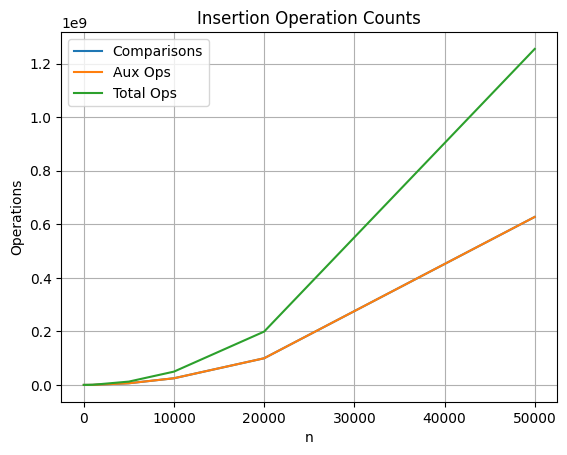

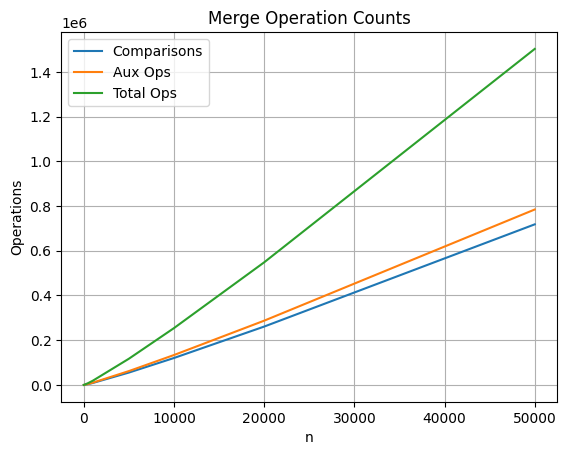

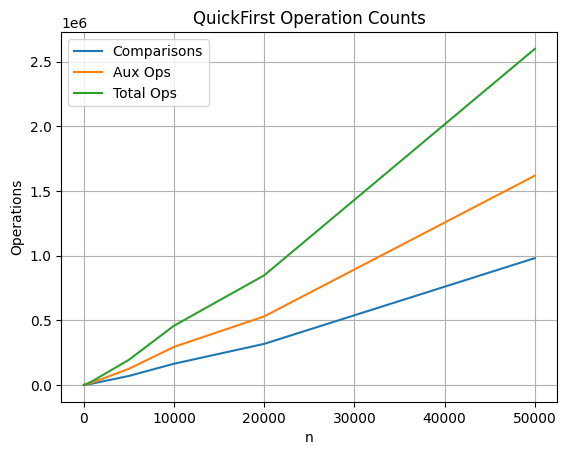

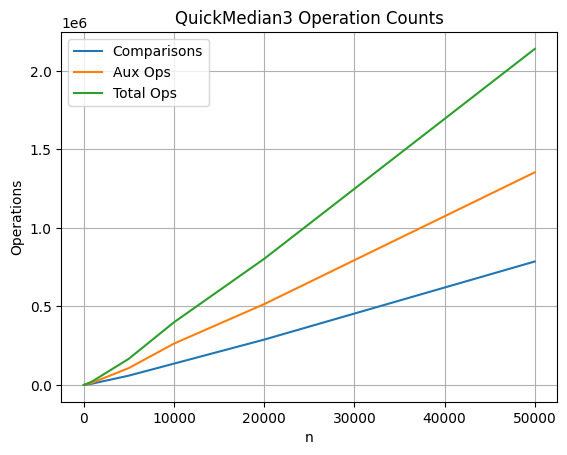

Insertion ≈ 1559.4772273254719 * n log n + -52538280.65329259
Merge ≈ 1.9250620918629016 * n log n + -654.3953279186197
QuickFirst ≈ 3.3019641557873816 * n log n + -7858.516346510579
QuickMedian3 ≈ 2.7473262532033287 * n log n + 4487.051438729591


In [19]:
def make_random(n):
    return [random.randint(0, 10**6) for _ in range(n)]


list_sizes = [10, 50, 100, 500, 1000, 5000, 10000, 20000, 50000]

algorithms = [
    ("Insertion", insertion_sort_count),
    ("Merge", merge_sort_count),
    ("QuickFirst", quick_sort_first_count),
    ("QuickMedian3", quick_sort_median3_count)
]

results = {}
for name, func in algorithms:
    results[name] = {"n": [], "comp": [], "aux": [], "total": []}
    for n in list_sizes:
        arr = make_random(n)
        comps, aux, total = func(arr)
        results[name]["n"].append(n)
        results[name]["comp"].append(comps)
        results[name]["aux"].append(aux)
        results[name]["total"].append(total)


for name, _ in algorithms:
    data = results[name]
    plt.figure()
    plt.plot(data["n"], data["comp"], label="Comparisons")
    plt.plot(data["n"], data["aux"], label="Aux Ops")
    plt.plot(data["n"], data["total"], label="Total Ops")
    plt.xlabel("n")
    plt.ylabel("Operations")
    plt.title(name + " Operation Counts")
    plt.legend()
    plt.grid(True)
    plt.show()


def fit_nlogn(n, ops):
    x = np.array([ni * np.log2(ni) for ni in n])
    y = np.array(ops)
    c = np.polyfit(x, y, 1)
    return c


for name, _ in algorithms:
    slope, intercept = fit_nlogn(results[name]["n"], results[name]["total"])
    print(name, "≈", slope, "* n log n +", intercept)

## Reflection
### Insertion Operation Count
As the number of elements in the list increases both the comparison plus the auxiliary operaion increases in significant amount
The auxiliary operations is small overall compared to the comparisons and total operations
At n = 50000, the total operations is 1.2 * 1e9 and the auxiliary operations is around 0.6 * 1e9, which is very significant compared to the rest of sorting techniques at that number of lists
### Merge Operation Count
Both the comparisons and the auxiliary operations increase linearly as seen from the graph and reaching around 0.75 * 1e6 operations at n = 50000. Both operations are almost the same entirely except that auxiliary operations take a bit higher operations than comparisons.
### Quick First Operation Counts
Better than Insertion sort but less than Merge. The Auxiliary operation reaches almost 1.6 * 1e6 operations at n = 50000 and the comparison reaching 1 * 1e6 operations. 
### QuickMedian3 Operation Counts
Both operations increase almost linearly. Aux Ops reaches around 1.4 * 1e6 at n = 50000 and Comparisons reach around 0.8 * 1e6 at n = 50000.